In [1]:
import pandas as pd
import numpy as np

inventory = pd.read_parquet(
    "../data/processed/inventory_clean.parquet"
)

weekly_sales = pd.read_parquet(
    "../data/processed/weekly_sales.parquet"
)

master_df = pd.read_parquet(
    "../data/processed/master_df.parquet"
)

In [3]:
latest_forecast = (

    weekly_sales

    .groupby("sku_id")

    .tail(1)[["sku_id", "seasonal_naive"]]

)

latest_forecast.head()

,sku_id,seasonal_naive
150,SKU00001,22.0
301,SKU00002,195.0
445,SKU00003,9.0
596,SKU00004,16.0
745,SKU00005,7.0


In [5]:
latest_forecast.rename(

    columns={

        "seasonal_naive": "forecast_demand"

    },

    inplace=True

)

In [7]:
risk_df = inventory.merge(

    latest_forecast,

    on="sku_id",

    how="left"

)

risk_df.head()

,store_id,sku_id,stock_on_hand,reorder_point,safety_stock,last_restock_date,forecast_demand
0,ST11,SKU02558,323,72,22,2025-05-17,10.0
1,ST21,SKU01031,236,67,14,2025-06-17,3.0
2,ST26,SKU02129,433,96,34,2025-05-20,10.0
3,ST19,SKU02907,178,34,13,2025-08-03,10.0
4,ST05,SKU01023,333,97,22,2025-07-12,4.0


In [9]:
conditions = [

    risk_df["forecast_demand"] > risk_df["stock_on_hand"],

    risk_df["stock_on_hand"] > 2 * risk_df["forecast_demand"]

]

actions = [

    "REORDER NOW",

    "MARKDOWN"

]

risk_df["recommended_action"] = np.select(

    conditions,

    actions,

    default="HEALTHY"

)

In [11]:
risk_df["recommended_action"].value_counts()

recommended_action
MARKDOWN       16554
REORDER NOW     3746
HEALTHY          928
Name: count, dtype: int64

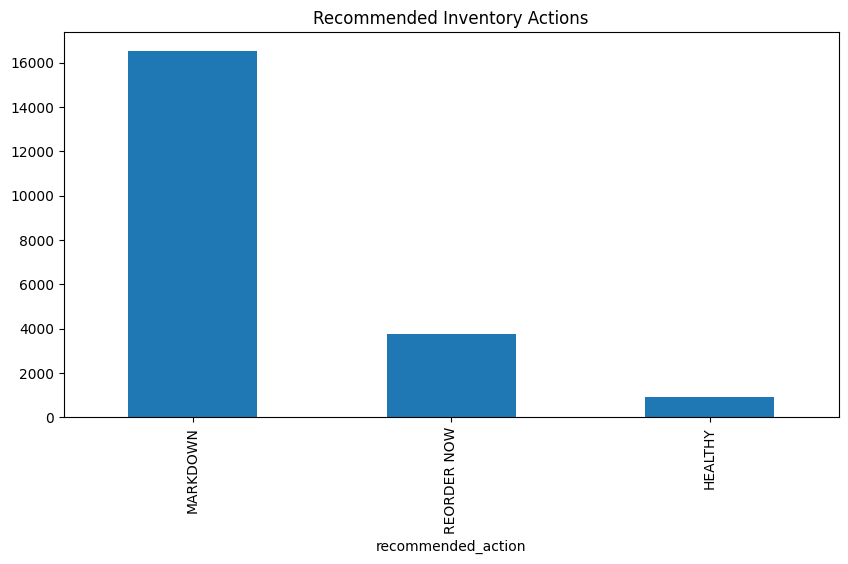

In [13]:
import matplotlib.pyplot as plt

risk_df["recommended_action"].value_counts().plot(

    kind="bar",

    figsize=(10, 5)

)

plt.title(

    "Recommended Inventory Actions"

)

plt.savefig(

    "../reports/images/recommended_actions.png",

    bbox_inches="tight"

)

plt.show()

In [15]:
risk_df["monthly_forecast"] = (

    risk_df["forecast_demand"] * 4

)

In [24]:
risk_df["stock_on_hand"] > 3 * risk_df["monthly_forecast"]

0         True
1         True
2         True
3         True
4         True
         ...  
21223    False
21224    False
21225    False
21226    False
21227    False
Length: 21228, dtype: bool

In [32]:
risk_df["stock_on_hand"] > 3 * risk_df["monthly_forecast"]

0         True
1         True
2         True
3         True
4         True
         ...  
21223    False
21224    False
21225    False
21226    False
21227    False
Length: 21228, dtype: bool

In [34]:
conditions = [

    risk_df["stock_on_hand"] < risk_df["forecast_demand"],

    risk_df["stock_on_hand"] < risk_df["reorder_point"],

    risk_df["stock_on_hand"] > 2 * risk_df["monthly_forecast"]

]

actions = [

    "REORDER NOW",

    "WATCH",

    "MARKDOWN"

]

risk_df["recommended_action"] = np.select(

    conditions,

    actions,

    default="HEALTHY"

)

In [36]:
risk_df["recommended_action"].value_counts()

recommended_action
MARKDOWN       12431
REORDER NOW     3746
HEALTHY         2897
WATCH           2154
Name: count, dtype: int64

In [38]:
total_products = len(risk_df)

markdown_pct = (

    risk_df["recommended_action"]

    .eq("MARKDOWN")

    .mean()

) * 100

reorder_pct = (

    risk_df["recommended_action"]

    .eq("REORDER NOW")

    .mean()

) * 100

healthy_pct = (

    risk_df["recommended_action"]

    .eq("HEALTHY")

    .mean()

) * 100

watch_pct = (

    risk_df["recommended_action"]

    .eq("WATCH")

    .mean()

) * 100

print(f"MARKDOWN: {markdown_pct:.2f}%")

print(f"REORDER NOW: {reorder_pct:.2f}%")

print(f"WATCH: {watch_pct:.2f}%")

print(f"HEALTHY: {healthy_pct:.2f}%")

MARKDOWN: 58.56%
REORDER NOW: 17.65%
WATCH: 10.15%
HEALTHY: 13.65%


In [40]:
risk_df.to_parquet(

    "../data/processed/risk_scoring.parquet",

    index=False

)

In [42]:
risk_df.shape

(21228, 9)

# Inventory Risk Scoring Insights

## Key Findings

- 58.56% of products are classified as MARKDOWN, indicating excess inventory relative to forecasted demand.

- 17.65% of products require immediate replenishment (REORDER NOW), representing a potential stockout risk.

- 10.15% of products are in the WATCH category because their stock levels are approaching the reorder threshold.

- Only 13.65% of products are currently in a healthy inventory state.

---

## Business Insights

- More than half of the inventory is overstocked, increasing storage and holding costs.

- Nearly one-fifth of products face stockout risk, which may lead to lost sales and customer dissatisfaction.

- Inventory planning needs to be optimized to balance product availability and inventory costs.

- The low percentage of healthy products suggests inefficiencies in current inventory management practices.

---

## Recommendations

- Launch promotional campaigns and discounts for MARKDOWN products.

- Prioritize procurement for products classified as REORDER NOW.

- Closely monitor WATCH products to avoid future stockouts.

- Improve demand forecasting and inventory planning strategies.

- Conduct periodic inventory audits to reduce excess stock and prevent lost sales.